In [21]:
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd 
import kagglehub
from pathlib import Path

In [22]:
house_data = pd.read_csv('Housing.csv')

# stat_house = house_data.describe()
house_datary= np.array(house_data)
house_datary

array([[13300000, 7420, 4, ..., 2, 'yes', 'furnished'],
       [12250000, 8960, 4, ..., 3, 'no', 'furnished'],
       [12250000, 9960, 3, ..., 2, 'yes', 'semi-furnished'],
       ...,
       [1750000, 3620, 2, ..., 0, 'no', 'unfurnished'],
       [1750000, 2910, 3, ..., 0, 'no', 'furnished'],
       [1750000, 3850, 3, ..., 0, 'no', 'unfurnished']],
      shape=(545, 13), dtype=object)

(545, 4)
(4,)


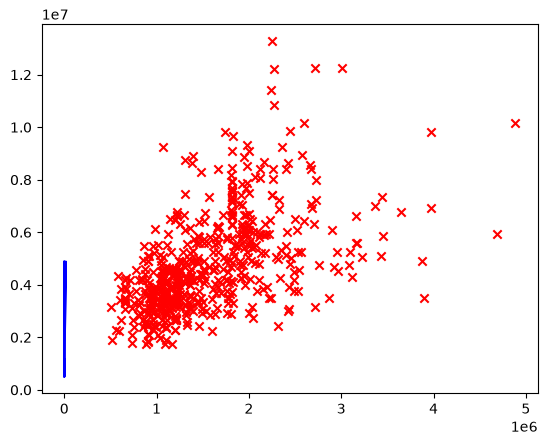

In [34]:
# y: The target column (Column 0: Price)
y = house_datary[:, 0].astype(float)

# X: The feature columns (Columns 1, 2, 3, and 4: Area, Bedrooms, Bathrooms, Stories)
x = house_datary[:, 1:5].astype(float)

w = np.array([300, 1000, 5000, 2000]) 
b = 300 

print(np.shape(x))
print(np.shape(w))


first_reg = np.dot(x,w) + b

first_reg

plt.scatter(first_reg,y, c = 'red' , marker = 'x')
plt.plot(x,first_reg, c = 'blue')

In [35]:
m = len(y)

cost_func = (1 / (2 * m)) * np.sum((first_reg - y)**2)
cost_func

np.float64(6448757139646.423)

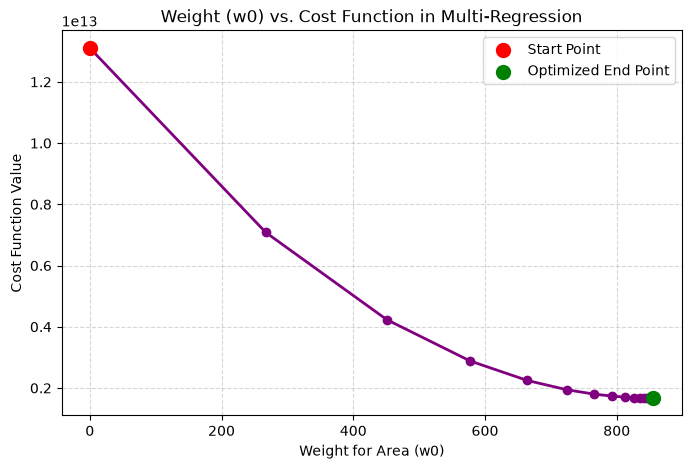

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Setup variables
w = np.zeros(4)  
b = 0.0  
learning_rate = 0.00000001  
epochs = 100  
m = len(y)  

# Lists to track history
cost_history = []
w_history = [] # This will store arrays of shape (4,)

# 2. Training Loop
for i in range(epochs):
    first_reg = np.dot(x, w) + b
    cost_func = (1 / (2 * m)) * np.sum((first_reg - y) ** 2)
    
    cost_history.append(cost_func)
    w_history.append(w.copy()) # .copy() ensures we save the actual values at this step

    error = first_reg - y
    w_gradient = (1 / m) * np.dot(x.T, error)
    b_gradient = (1 / m) * np.sum(error)

    w = w - (learning_rate * w_gradient)
    b = b - (learning_rate * b_gradient)

# 3. Convert w_history to a NumPy array to easily extract columns
w_history = np.array(w_history)

# Extract JUST the weight for Feature 0 (Area)
# w_history[:, 0] grabs column 0 from your history matrix
w_area_history = w_history[:, 0]

# 4. Now the plotting code will work cleanly!
plt.figure(figsize=(8, 5))
plt.plot(w_area_history, cost_history, color='purple', marker='o', linestyle='-', linewidth=2)

# Mark the starting point and final ending point
plt.scatter(w_area_history[0], cost_history[0], color='red', s=100, label='Start Point', zorder=5)
plt.scatter(w_area_history[-1], cost_history[-1], color='green', s=100, label='Optimized End Point', zorder=5)

plt.xlabel("Weight for Area (w0)")
plt.ylabel("Cost Function Value")
plt.title("Weight (w0) vs. Cost Function in Multi-Regression")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()


In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Setup
w = np.zeros(4)  
b = 0.0  
learning_rate = 0.00000001  
epochs = 100  
m = len(y)  

# History trackers
cost_history = []
w0_history = []  # Track just the area weight
b_history = []   # Track the bias

for i in range(epochs):
    first_reg = np.dot(x, w) + b
    cost_func = (1 / (2 * m)) * np.sum((first_reg - y) ** 2)
    
    cost_history.append(cost_func)
    w0_history.append(w[0])
    b_history.append(b)

    error = first_reg - y
    w_gradient = (1 / m) * np.dot(x.T, error)
    b_gradient = (1 / m) * np.sum(error)

    w = w - (learning_rate * w_gradient)
    b = b - (learning_rate * b_gradient)


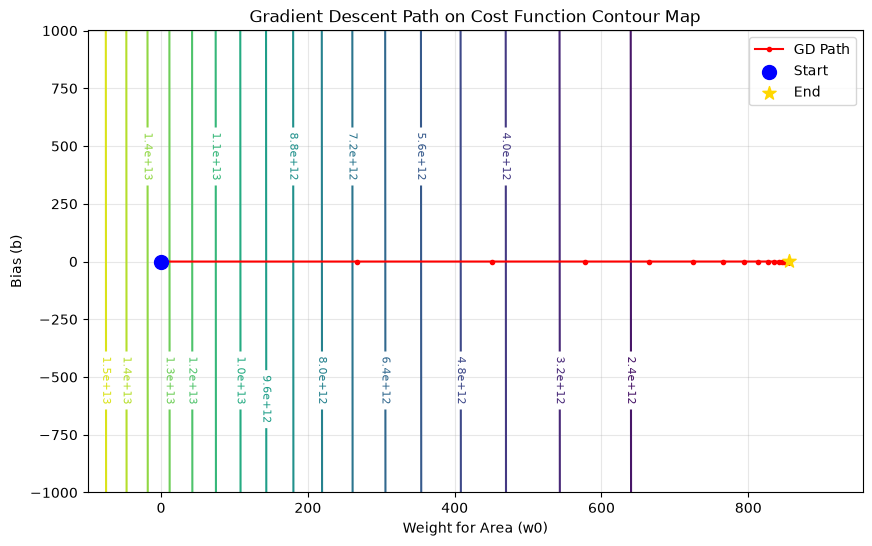

In [41]:
# 1. Create a grid of values around your history path
# Adjust these range numbers if your weights go outside these bounds
w0_vals = np.linspace(min(w0_history) - 100, max(w0_history) + 100, 100)
b_vals = np.linspace(min(b_history) - 1000, max(b_history) + 1000, 100)

# Create the 2D coordinate grid
W0, B = np.meshgrid(w0_vals, b_vals)
Z_cost = np.zeros(W0.shape)

# 2. Fill the grid with cost calculations
# We hold w1, w2, and w3 static at their final trained values
for i in range(W0.shape[0]):
    for j in range(W0.shape[1]):
        # Reconstruct a prediction using the grid w0 and grid b
        # x[:, 0] is Area, x[:, 1:] are the remaining 3 features
        pred = (W0[i, j] * x[:, 0]) + np.dot(x[:, 1:], w[1:]) + B[i, j]
        Z_cost[i, j] = (1 / (2 * m)) * np.sum((pred - y) ** 2)

# 3. Create the Contour Plot
plt.figure(figsize=(10, 6))

# Draw the contour lines (levels=20 adds 20 rings to the 'bowl')
contours = plt.contour(W0, B, Z_cost, levels=20, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8, fmt='%1.1e')

# 4. Overlay the actual Gradient Descent Path
plt.plot(w0_history, b_history, color='red', marker='o', markersize=3, label='GD Path')
plt.scatter(w0_history[0], b_history[0], color='blue', s=100, label='Start', zorder=5)
plt.scatter(w0_history[-1], b_history[-1], color='gold', s=100, marker='*', label='End', zorder=5)

# Labels and Details
plt.xlabel("Weight for Area (w0)")
plt.ylabel("Bias (b)")
plt.title("Gradient Descent Path on Cost Function Contour Map")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [43]:
# Calculate mean and standard deviation for each feature
mu = np.mean(x, axis=0)
sigma = np.std(x, axis=0)

# Scale your x data
x_scaled = (x - mu) / sigma
mu
sigma
x_scaled

array([[ 1.04672629,  1.40341936,  1.42181174,  1.37821692],
       [ 1.75700953,  1.40341936,  5.40580863,  2.53202371],
       [ 2.21823241,  0.04727831,  1.42181174,  0.22441013],
       ...,
       [-0.70592066, -1.30886273, -0.57018671, -0.92939666],
       [-1.03338891,  0.04727831, -0.57018671, -0.92939666],
       [-0.5998394 ,  0.04727831, -0.57018671,  0.22441013]],
      shape=(545, 4))

In [44]:
# 1. New house details: 3000 sqft, 3 beds, 2 baths, 2 stories
new_house = np.array([3000, 3, 2, 2])

# 2. Scale it (Only do this if you scaled your training data!)
new_house_scaled = (new_house - mu) / sigma

# 3. Calculate the predicted price
predicted_price = np.dot(new_house_scaled, w) + b
print(f"Predicted Price: ${predicted_price:,.2f}")


Predicted Price: $-846.49


In [45]:
print("Current weights (w):", w)
print("Current bias (b):", b)



Current weights (w): [855.70837026   1.78793656   0.95452669   1.45428803]
Current bias (b): 0.5004896823246243
